In [52]:
import sys
import os

# Ensure local packages (models, lib_QEC) are importable
for p in [os.path.abspath(".." ), os.path.abspath(".")]:
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import matplotlib.pyplot as plt
import os
import json
import warnings

# Lipkin model — one-hot encoding (N+1 qubits, N+1 physical states)
from models.Lipkin_onehot import OptimizedLipkinSimulation
# Exact diag reference from the (N+1)-dimensional symmetric-subspace model
from models.Lipkin import LipkinHamiltonian, diabolic_points, qpt_line

# Qiskit core
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Qiskit Aer (simulation)
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as AerSampler

# Plotting setup
plt.rcParams.update({
    'text.usetex': False,
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 13,
    'axes.titlesize': 13,
})

print('All imports successful.')

All imports successful.


In [53]:
# ========================
# Configuration
# ========================

# Lipkin model parameters
N_PARTICLES = 6             # N particles -> N+1 qubits (one-hot encoding)

# Driving path: (lambda_0, chi_0) -> (lambda_f, chi_f)
LAM_0, CHI_0 = -0.5, 0.0    # initial point
LAM_F, CHI_F = -0.3, 1.5    # final point (crosses QPT)

# Spectrum parameters
N_S_POINTS = 15               # production: 30
N_LEVELS = 3                 # max N_PARTICLES + 1
N_EXACT_POINTS = 30          # production: 200

# SQD parameters
SQD_SHOTS = 50000             # production: 100000

# Adiabatic circuit parameters
T_SCALE = 10.0                # T_evolve = T_SCALE * s_end
N_STEPS_SCALE = 3            # n_steps = max(1, int(N_STEPS_SCALE * s_end))

# Hardware parameters
RUN_ON_HARDWARE = True
BACKEND_NAME = 'ibm_brussels'
HW_N_S_POINTS = N_EXACT_POINTS
HW_SHOTS = SQD_SHOTS
HW_WALLTIME = "12m"

# Results directory
RESULTS_DIR = 'results_lipkin_spectrum'
os.makedirs(RESULTS_DIR, exist_ok=True)

In [54]:
if RUN_ON_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService(name="Research-UK-eu")
    backend_hw = service.backend(BACKEND_NAME)
    print(f'Connected to {backend_hw.name} ({backend_hw.num_qubits} qubits)')

Connected to ibm_brussels (127 qubits)


In [45]:
# ========================
# Lipkin model initialization and driving path
# ========================

sim = OptimizedLipkinSimulation(N_PARTICLES)
num_qubits = sim.num_qubits  # N + 1

print(f'Lipkin model: N = {N_PARTICLES} particles, {num_qubits} qubits (one-hot)')
print(f'Physical Hilbert space: {N_PARTICLES + 1} states')
print(f'Qubit Hilbert space: 2^{num_qubits} = {2**num_qubits} states')
print(f'N_LEVELS = {N_LEVELS} (max {N_PARTICLES + 1})')

def driving_path(s):
    """Linear driving path: s in [0, 1] -> (lam, chi)"""
    lam = LAM_0 + s * (LAM_F - LAM_0)
    chi = CHI_0 + s * (CHI_F - CHI_0)
    return lam, chi

# Set of valid physical (one-hot) bitstrings
one_hot_set = {format(1 << m, f'0{num_qubits}b') for m in range(num_qubits)}

print(f'\nDriving path: ({LAM_0}, {CHI_0}) -> ({LAM_F}, {CHI_F})')
print(f'Physical one-hot bitstrings: {len(one_hot_set)} states')

Lipkin model: N = 6 particles, 7 qubits (one-hot)
Physical Hilbert space: 7 states
Qubit Hilbert space: 2^7 = 128 states
N_LEVELS = 3 (max 7)

Driving path: (-0.5, 0.0) -> (-0.3, 1.5)
Physical one-hot bitstrings: 7 states


# 1. Exact Diagonalization (Reference Lines)

In [46]:
print("Computing exact diagonalization...")
s_values_exact = np.linspace(0, 1, N_EXACT_POINTS)
exact_energies = np.zeros((N_EXACT_POINTS, N_LEVELS))

for i, s in enumerate(s_values_exact):
    lam, chi = driving_path(s)
    H_phys = sim.hamiltonian_matrix(lam, chi)  # (N+1) x (N+1)
    exact_energies[i, :] = np.linalg.eigvalsh(H_phys)[:N_LEVELS]

print(f"Computed {N_EXACT_POINTS} exact points, {N_LEVELS} levels each.")

Computing exact diagonalization...
Computed 30 exact points, 3 levels each.


In [47]:
def onehot_bitstring_to_index(bs, num_qubits):
    """Convert a one-hot bitstring to its Dicke index (which bit is set)."""
    val = int(bs, 2)
    for m in range(num_qubits):
        if val == (1 << m):
            return m
    return None  # not a valid one-hot bitstring


def sqd_spectrum_onehot(counts, H_physical, n_levels=3):
    """
    SQD for one-hot encoding: project H_physical (N+1 x N+1) onto the
    subspace of sampled physical (one-hot) bitstrings.

    No SparsePauliOp needed — works directly with the (N+1)-dim matrix.
    """
    # Filter to physical one-hot bitstrings
    sampled_indices = []
    for bs in counts:
        idx = onehot_bitstring_to_index(bs, num_qubits)
        if idx is not None:
            sampled_indices.append(idx)

    sampled_indices = sorted(set(sampled_indices))

    if len(sampled_indices) < 2:
        return np.full(n_levels, np.nan)

    # Project: take the submatrix of H_physical
    H_sub = H_physical[np.ix_(sampled_indices, sampled_indices)]
    eigenvalues = np.sort(np.linalg.eigvalsh(H_sub).real)

    if len(eigenvalues) < n_levels:
        eigenvalues = np.concatenate([eigenvalues, np.full(n_levels - len(eigenvalues), np.nan)])

    return eigenvalues[:n_levels]


def build_adiabatic_circuit_to_s(sim, s_end, driving_path):
    """
    Build an adiabatic circuit that evolves from s=0 to s=s_end.
    Uses the one-hot encoding with efficient O(N) state prep and XY gates.
    """
    def gamma_path(t, T):
        fraction = (t / T) if T > 0 else 0
        curr_s = fraction * s_end
        return driving_path(curr_s)

    T_evolve = T_SCALE * s_end
    n_steps = max(1, int(N_STEPS_SCALE * s_end))

    qc = sim.build_adiabatic_circuit(gamma_path, T=T_evolve, n_steps=n_steps)
    qc.measure_all()
    return qc


print('SQD helper functions defined.')
print(f'Physical one-hot bitstrings: {len(one_hot_set)} states')

SQD helper functions defined.
Physical one-hot bitstrings: 7 states


# 2. SQD Simulation (Ideal Sampler)

Sample bitstrings from adiabatic circuits using an **ideal (noiseless) simulator**,
then use SQD to extract the spectrum classically.

In [48]:
print("=== SQD Simulation (ideal sampler) ===")
s_values_sqd = np.linspace(1.0 / N_S_POINTS, 1, N_S_POINTS)
sqd_sim_energies = np.zeros((N_S_POINTS, N_LEVELS))

# Physical state coverage tracking
subspace_data_sim = {
    'n_physical_states': np.zeros(N_S_POINTS, dtype=int),   # how many of N+1 one-hot states sampled
    'physical_prob': np.zeros(N_S_POINTS),                   # fraction of shots landing on physical states
}

# Ideal simulator
aer_sim = AerSimulator()
aer_sampler = AerSampler()
pm_sim = generate_preset_pass_manager(optimization_level=0, target=aer_sim.target)

for i, s_end in enumerate(s_values_sqd):
    lam, chi = driving_path(s_end)
    H_physical = sim.hamiltonian_matrix(lam, chi)  # (N+1) x (N+1)

    # Build adiabatic circuit to s_end and measure
    qc = build_adiabatic_circuit_to_s(sim, s_end, driving_path)
    isa_qc = pm_sim.run(qc)

    # Sample bitstrings
    result = aer_sampler.run([isa_qc], shots=SQD_SHOTS).result()
    counts = result[0].data.meas.get_counts()

    # --- Bitstring statistics ---
    total_shots = sum(counts.values())
    physical_counts = {bs: c for bs, c in counts.items() if bs in one_hot_set}
    n_phys_shots = sum(physical_counts.values())
    n_phys_states = len(physical_counts)
    phys_prob = n_phys_shots / total_shots

    subspace_data_sim['n_physical_states'][i] = n_phys_states
    subspace_data_sim['physical_prob'][i] = phys_prob

    print(f'\n  s={s_end:.3f} | {total_shots} shots, {len(counts)} unique bitstrings')
    print(f'    Physical: {n_phys_shots}/{total_shots} shots '
          f'({100*phys_prob:.1f}%), '
          f'{n_phys_states}/{num_qubits} one-hot states')
    for bs in sorted(physical_counts, key=physical_counts.get, reverse=True):
        print(f'      {bs}  ({physical_counts[bs]:5d} shots)')

    # SQD diagonalization (directly on the (N+1)-dim Hamiltonian)
    evs = sqd_spectrum_onehot(counts, H_physical, n_levels=N_LEVELS)
    sqd_sim_energies[i, :] = evs

    e_str = ', '.join(f'{e:.3f}' for e in evs)
    print(f'    => SQD energies: [{e_str}]')

print("\nDone.")

=== SQD Simulation (ideal sampler) ===

  s=0.067 | 50000 shots, 4 unique bitstrings
    Physical: 50000/50000 shots (100.0%), 4/7 one-hot states
      1000000  (49931 shots)
      0010000  (   63 shots)
      0000100  (    3 shots)
      0100000  (    3 shots)
    => SQD energies: [-2.889, -1.683, -0.574]

  s=0.133 | 50000 shots, 5 unique bitstrings
    Physical: 50000/50000 shots (100.0%), 5/7 one-hot states
      1000000  (47565 shots)
      0010000  ( 2145 shots)
      0000100  (  225 shots)
      0100000  (   53 shots)
      0001000  (   12 shots)
    => SQD energies: [-2.893, -1.729, -0.658]

  s=0.200 | 50000 shots, 6 unique bitstrings
    Physical: 50000/50000 shots (100.0%), 6/7 one-hot states
      1000000  (43451 shots)
      0010000  ( 4877 shots)
      0000100  ( 1431 shots)
      0001000  (  124 shots)
      0100000  (  101 shots)
      0000010  (   16 shots)
    => SQD energies: [-2.897, -1.767, -0.775]

  s=0.267 | 50000 shots, 6 unique bitstrings
    Physical: 50000/5

# 3. SQD on Real Hardware

Same adiabatic circuits as above, but sampled on **real IBM Quantum hardware**.
All circuits are transpiled and submitted in a single batched `Session`.

In [24]:
if RUN_ON_HARDWARE:
    from qiskit_ibm_runtime import (
        Session,
        SamplerV2 as HWSampler,
    )

    pm_hw_real = generate_preset_pass_manager(
        optimization_level=3, backend=backend_hw
    )

    s_values_real_hw = np.linspace(1.0 / N_S_POINTS, 1, N_S_POINTS)
    energies_sqd_real_hw = np.zeros((len(s_values_real_hw), N_LEVELS))

    print(f'=== SQD on Real Hardware: Lipkin N={N_PARTICLES} ===')
    print(f'Backend: {backend_hw.name}, Walltime: {HW_WALLTIME}')

    circuits_to_run = []
    for i, s_end in enumerate(s_values_real_hw):
        qc = build_adiabatic_circuit_to_s(sim, s_end, driving_path)
        isa_qc = pm_hw_real.run(qc)
        circuits_to_run.append(isa_qc)
        print(f'  s={s_end:.2f}: depth={isa_qc.depth()}, '
              f'2Q gates={isa_qc.size(lambda x: x.operation.num_qubits == 2)}')

    with Session(backend=backend_hw, max_time=HW_WALLTIME) as session:
        sampler_hw = HWSampler(mode=session)

        print(f'\nSubmitting {len(circuits_to_run)} sampling jobs...')
        job_result = sampler_hw.run(circuits_to_run, shots=HW_SHOTS)
        all_results = job_result.result()

        print('Processing SQD results...\n')
        for i, (s_end, result_data) in enumerate(zip(s_values_real_hw, all_results)):
            counts = result_data.data.meas.get_counts()

            lam, chi = driving_path(s_end)
            H_physical = sim.hamiltonian_matrix(lam, chi)
            evs = sqd_spectrum_onehot(counts, H_physical, n_levels=N_LEVELS)
            energies_sqd_real_hw[i] = evs

            total = sum(counts.values())
            n_phys_shots = sum(counts[bs] for bs in counts if bs in one_hot_set)
            n_phys_states = sum(1 for bs in counts if bs in one_hot_set)
            prob_physical = n_phys_shots / total
            e_str = ', '.join(f'{e:.3f}' for e in evs)
            print(f'  s={s_end:.2f}: E=[{e_str}], '
                  f'Phys: {n_phys_shots}/{total} ({prob_physical:.1%}), '
                  f'{n_phys_states}/{num_qubits} states')

    sqd_real_hw_results = {
        's_values': s_values_real_hw,
        'energies': energies_sqd_real_hw,
    }
    print('\nHardware SQD complete!')
else:
    sqd_real_hw_results = None
    print('Hardware submission skipped (RUN_ON_HARDWARE = False).')

=== SQD on Real Hardware: Lipkin N=6 ===
Backend: ibm_brussels, Walltime: 12m
  s=0.07: depth=124, 2Q gates=47
  s=0.13: depth=124, 2Q gates=47
  s=0.20: depth=125, 2Q gates=47
  s=0.27: depth=125, 2Q gates=47
  s=0.33: depth=114, 2Q gates=47
  s=0.40: depth=124, 2Q gates=47
  s=0.47: depth=125, 2Q gates=44
  s=0.53: depth=114, 2Q gates=47
  s=0.60: depth=125, 2Q gates=44
  s=0.67: depth=189, 2Q gates=83
  s=0.73: depth=218, 2Q gates=82
  s=0.80: depth=220, 2Q gates=80
  s=0.87: depth=178, 2Q gates=83
  s=0.93: depth=189, 2Q gates=83
  s=1.00: depth=240, 2Q gates=119

Submitting 15 sampling jobs...
Processing SQD results...

  s=0.07: E=[-2.889, -1.704, -0.591], Phys: 8651/50000 (17.3%), 7/7 states
  s=0.13: E=[-2.893, -1.729, -0.661], Phys: 7224/50000 (14.4%), 7/7 states
  s=0.20: E=[-2.897, -1.767, -0.775], Phys: 5020/50000 (10.0%), 7/7 states
  s=0.27: E=[-2.902, -1.820, -0.950], Phys: 3390/50000 (6.8%), 7/7 states
  s=0.33: E=[-2.907, -1.893, -1.219], Phys: 5069/50000 (10.1%), 7/7 

# 4. Save Raw Hardware Results

In [25]:
from __future__ import annotations
from pathlib import Path
import json
from typing import Any, Dict, List, Optional, Sequence, Tuple, Union
import numpy as np

# hardware_results_io.py




def _as_path(results_dir: Union[str, Path]) -> Path:
    p = Path(results_dir)
    p.mkdir(parents=True, exist_ok=True)
    return p


def extract_counts_from_sampler_results(
    sampler_results: Any,
) -> List[Dict[str, int]]:
    """
    Extract a list of counts dicts from Qiskit SamplerV2 results.

    Accepts:
      - PrimitiveResult (iterable of SamplerPubResult)
      - list/tuple of SamplerPubResult
    """
    pubs = list(sampler_results)
    counts_list: List[Dict[str, int]] = []
    for pub in pubs:
        # Qiskit SamplerV2: pub.data.meas.get_counts()
        counts = pub.data.meas.get_counts()
        # Ensure plain Python ints for JSON portability
        counts_list.append({str(k): int(v) for k, v in counts.items()})
    return counts_list


def save_real_hardware_results(
    results_dir: Union[str, Path],
    *,
    s_values: Union[Sequence[float], np.ndarray],
    sampler_results: Any,
    energies: Optional[Union[Sequence[Sequence[float]], np.ndarray]] = None,
    meta: Optional[Dict[str, Any]] = None,
    prefix: str = "real_hw",
) -> Tuple[Path, Path]:
    """
    Save raw hardware sampling (counts) + optional energies.

    Writes:
      - {prefix}_counts.json  (raw counts + metadata)
      - {prefix}_arrays.npz   (s_values + optional energies)
    """
    outdir = _as_path(results_dir)

    s_arr = np.asarray(s_values, dtype=float)
    counts_list = extract_counts_from_sampler_results(sampler_results)

    meta_out: Dict[str, Any] = dict(meta or {})
    meta_out.update(
        {
            "prefix": prefix,
            "n_points": int(len(s_arr)),
        }
    )

    json_path = outdir / f"{prefix}_counts.json"
    payload = {
        "meta": meta_out,
        "s_values": s_arr.tolist(),
        "counts": counts_list,
    }
    if energies is not None:
        payload["energies"] = np.asarray(energies, dtype=float).tolist()

    json_path.write_text(json.dumps(payload, indent=2))

    npz_path = outdir / f"{prefix}_arrays.npz"
    npz_kwargs: Dict[str, Any] = {"s_values": s_arr}
    if energies is not None:
        npz_kwargs["energies"] = np.asarray(energies, dtype=float)
    np.savez(npz_path, **npz_kwargs)

    return json_path, npz_path


def load_real_hardware_results(
    results_dir: Union[str, Path],
    *,
    prefix: str = "real_hw",
) -> Dict[str, Any]:
    """
    Load previously saved hardware results.

    Returns dict with keys:
      - meta (dict)
      - s_values (np.ndarray)
      - counts (list[dict[str,int]])
      - energies (np.ndarray) if present
    """
    outdir = _as_path(results_dir)
    json_path = outdir / f"{prefix}_counts.json"
    if not json_path.exists():
        raise FileNotFoundError(f"Missing file: {json_path}")

    payload = json.loads(json_path.read_text())

    out: Dict[str, Any] = {
        "meta": payload.get("meta", {}),
        "s_values": np.asarray(payload["s_values"], dtype=float),
        "counts": [{str(k): int(v) for k, v in d.items()} for d in payload["counts"]],
    }
    if "energies" in payload:
        out["energies"] = np.asarray(payload["energies"], dtype=float)

    return out

In [26]:
if sqd_real_hw_results is not None:
    save_real_hardware_results(
        "QC_driving_spectrum_SQD_original_results",
        s_values=s_values_real_hw,
        sampler_results=all_results,
        energies=energies_sqd_real_hw,
    )
    print('Raw hardware results saved.')
else:
    print('No hardware results to save.')
if sqd_real_hw_results is None:
    for results_dir in ["QC_driving_spectrum_SQD_original_results", "../QC_driving_spectrum_SQD_original_results"]:
        if os.path.exists(results_dir):
            try:
                sqd_real_hw_results = load_real_hardware_results(results_dir)
                print(f"Loaded cached real hardware results from {results_dir}.")
                break
            except Exception as e:
                print(f"Could not load from {results_dir}: {e}")


Raw hardware results saved.


# 5. Comparison Plot: Exact vs Ideal SQD vs Hardware SQD

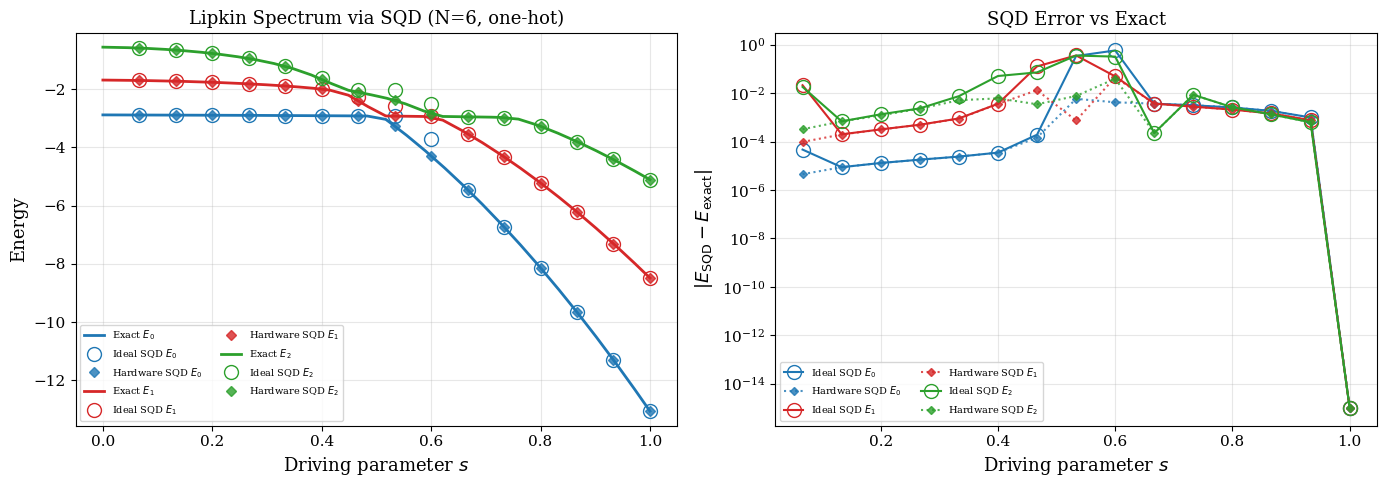

In [27]:
colors_level = ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e', '#9467bd', '#8c564b']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left: Spectrum overlay ---
ax = axes[0]
s_plot_fine = np.linspace(0, 1, 500)
for k in range(N_LEVELS):
    e_fine = np.interp(s_plot_fine, s_values_exact, exact_energies[:, k])
    ax.plot(s_plot_fine, e_fine, '-', color=colors_level[k],
            linewidth=2, label=f'Exact $E_{k}$')
    ax.plot(s_values_sqd, sqd_sim_energies[:, k], 'o', color=colors_level[k],
            markersize=10, fillstyle='none', label=f'Ideal SQD $E_{k}$')
    if sqd_real_hw_results is not None:
        ax.plot(sqd_real_hw_results['s_values'],
                sqd_real_hw_results['energies'][:, k],
                'D', color=colors_level[k], markersize=5, alpha=0.8,
                label=f'Hardware SQD $E_{k}$')

ax.set_xlabel(r'Driving parameter $s$')
ax.set_ylabel('Energy')
ax.set_title(f'Lipkin Spectrum via SQD (N={N_PARTICLES}, one-hot)')
ax.legend(fontsize=7, ncol=2, loc='best')
ax.set_ylim(exact_energies[:, :N_LEVELS].min() - 0.5, exact_energies[:, :N_LEVELS].max() + 0.5)
ax.grid(True, alpha=0.3)

# --- Right: Error ---
ax2 = axes[1]
for k in range(N_LEVELS):
    e_exact_interp = np.interp(s_values_sqd, s_values_exact, exact_energies[:, k])

    error_sim = np.abs(sqd_sim_energies[:, k] - e_exact_interp)
    ax2.semilogy(s_values_sqd, error_sim + 1e-15, 'o-', color=colors_level[k],
                 markersize=10, fillstyle='none', label=f'Ideal SQD $E_{k}$')

    if sqd_real_hw_results is not None:
        s_hw = sqd_real_hw_results['s_values']
        e_hw = sqd_real_hw_results['energies'][:, k]
        e_exact_interp_hw = np.interp(s_hw, s_values_exact, exact_energies[:, k])
        error_real_hw = np.abs(e_hw - e_exact_interp_hw)
        ax2.semilogy(s_hw, error_real_hw + 1e-15, 'D:', color=colors_level[k],
                     markersize=4, alpha=0.8, label=f'Hardware SQD $E_{k}$')

ax2.set_xlabel(r'Driving parameter $s$')
ax2.set_ylabel(r'$|E_{\mathrm{SQD}} - E_{\mathrm{exact}}|$')
ax2.set_title('SQD Error vs Exact')
ax2.legend(fontsize=7, ncol=2, loc='best')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/sqd_spectrum_comparison.pdf', bbox_inches='tight')
plt.show()

# 6. Physical State Coverage (Ideal SQD)

How many of the N+1 physical (one-hot) states does the ideal circuit sample,
and what fraction of shots land on physical bitstrings?

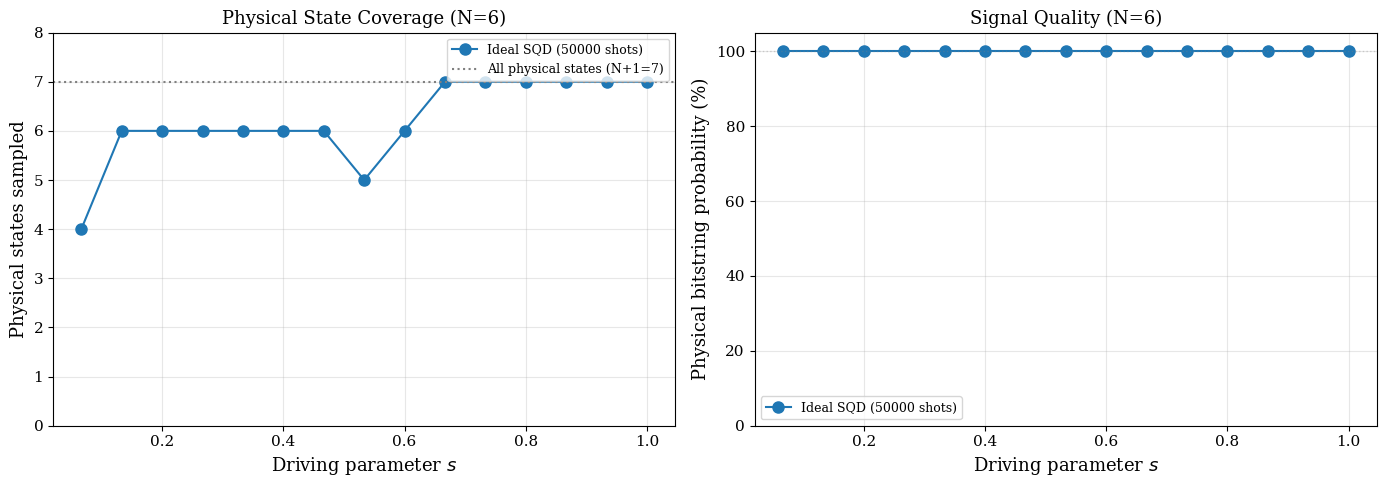

In [28]:
fig_sub, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(14, 5))

# --- Left: Physical state coverage (how many of N+1 states sampled) ---
ax_l.plot(s_values_sqd, subspace_data_sim['n_physical_states'], 'o-',
          color='#1f77b4', markersize=8, label=f'Ideal SQD ({SQD_SHOTS} shots)')
ax_l.axhline(y=num_qubits, color='gray', linestyle=':', linewidth=1.5,
             label=f'All physical states (N+1={num_qubits})')
ax_l.set_xlabel(r'Driving parameter $s$')
ax_l.set_ylabel('Physical states sampled')
ax_l.set_title(f'Physical State Coverage (N={N_PARTICLES})')
ax_l.set_ylim(0, num_qubits + 1)
ax_l.legend(fontsize=9)
ax_l.grid(True, alpha=0.3)

# --- Right: Physical bitstring probability ---
ax_r.plot(s_values_sqd, 100 * subspace_data_sim['physical_prob'], 'o-',
          color='#1f77b4', markersize=8, label=f'Ideal SQD ({SQD_SHOTS} shots)')
ax_r.axhline(y=100, color='gray', linestyle=':', linewidth=1, alpha=0.3)
ax_r.set_xlabel(r'Driving parameter $s$')
ax_r.set_ylabel('Physical bitstring probability (%)')
ax_r.set_title(f'Signal Quality (N={N_PARTICLES})')
ax_r.set_ylim(0, 105)
ax_r.legend(fontsize=9)
ax_r.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/sqd_physical_coverage.pdf', bbox_inches='tight')
plt.show()

# 7. SQD Robustness: How Does Missing States Affect the Spectrum?

For fixed N=15 at s=1.0, we systematically remove Dicke states from
the SQD projection and measure how the spectrum degrades.

Three removal strategies:
- **Least populated first**: remove states with smallest ground-state weight (realistic — these are hardest to sample)
- **Most populated first**: remove states with largest weight (worst case)
- **Random**: average over random removal orderings

This reveals whether SQD has a graceful degradation or a sharp cliff,
and whether the accuracy depends on *which* states are missing.

In [55]:
print("=== SQD Robustness Study (N=15, s=1.0) ===\n")

N_rob = 15
s_rob = 1.0
n_levels_rob = N_LEVELS
n_random_trials = 50

sim_rob = OptimizedLipkinSimulation(N_rob)
nq_rob = sim_rob.num_qubits  # 16

lam_r, chi_r = driving_path(s_rob)
H_rob = sim_rob.hamiltonian_matrix(lam_r, chi_r)
exact_evs_rob = np.sort(np.linalg.eigvalsh(H_rob))[:n_levels_rob]

# Ground state amplitudes in Dicke basis
gs_amplitudes = sim_rob.ground_state(lam_r, chi_r)
gs_probs = np.abs(gs_amplitudes)**2

print(f'Exact energies: {exact_evs_rob}')
print(f'\nGround state Dicke distribution (|c_m|^2):')
for m in range(nq_rob):
    bar = '#' * int(gs_probs[m] * 100)
    print(f'  m={m:2d}: {gs_probs[m]:.4f}  {bar}')

# Sort states by ground-state weight
order_least_pop = np.argsort(gs_probs)            # least populated first
order_most_pop = np.argsort(gs_probs)[::-1]        # most populated first

all_states = set(range(nq_rob))

# --- Strategy 1 & 2: Systematic removal ---
def sqd_with_states(H, keep_indices, n_levels):
    """Diagonalize H projected onto keep_indices."""
    if len(keep_indices) < 2:
        return np.full(n_levels, np.nan)
    idx = sorted(keep_indices)
    H_sub = H[np.ix_(idx, idx)]
    evs = np.sort(np.linalg.eigvalsh(H_sub).real)
    if len(evs) < n_levels:
        evs = np.concatenate([evs, np.full(n_levels - len(evs), np.nan)])
    return evs[:n_levels]

results_least = {'n_kept': [], 'errors': [], 'removed': []}
results_most = {'n_kept': [], 'errors': [], 'removed': []}

print(f'\n--- Least populated first removal ---')
removed_so_far = []
for k in range(nq_rob - 1):  # remove 0, 1, ..., N-1 states
    keep = sorted(all_states - set(removed_so_far))
    evs = sqd_with_states(H_rob, keep, n_levels_rob)
    errors = np.abs(evs - exact_evs_rob)
    results_least['n_kept'].append(len(keep))
    results_least['errors'].append(errors)
    results_least['removed'].append(list(removed_so_far))

    if k < 5 or len(keep) <= n_levels_rob + 1:
        e_str = ', '.join(f'{e:.3f}' for e in evs)
        err_str = ', '.join(f'{e:.2e}' for e in errors)
        rm_str = str(removed_so_far) if removed_so_far else '[]'
        print(f'  kept={len(keep):2d}/{nq_rob} | removed={rm_str}')
        print(f'    E=[{e_str}]  err=[{err_str}]')

    if k < nq_rob - 1:
        removed_so_far.append(order_least_pop[k])

print(f'\n--- Most populated first removal ---')
removed_so_far = []
for k in range(nq_rob - 1):
    keep = sorted(all_states - set(removed_so_far))
    evs = sqd_with_states(H_rob, keep, n_levels_rob)
    errors = np.abs(evs - exact_evs_rob)
    results_most['n_kept'].append(len(keep))
    results_most['errors'].append(errors)
    results_most['removed'].append(list(removed_so_far))

    if k < 5 or len(keep) <= n_levels_rob + 1:
        e_str = ', '.join(f'{e:.3f}' for e in evs)
        err_str = ', '.join(f'{e:.2e}' for e in errors)
        rm_str = str(removed_so_far) if removed_so_far else '[]'
        print(f'  kept={len(keep):2d}/{nq_rob} | removed={rm_str}')
        print(f'    E=[{e_str}]  err=[{err_str}]')

    if k < nq_rob - 1:
        removed_so_far.append(order_most_pop[k])

# --- Strategy 3: Random removal (averaged) ---
print(f'\n--- Random removal ({n_random_trials} trials per k) ---')
rng = np.random.default_rng(42)
results_random_mean = {'n_kept': [], 'error_mean': [], 'error_std': []}

for n_remove in range(nq_rob - 1):
    n_keep = nq_rob - n_remove
    trial_errors = []
    for _ in range(n_random_trials):
        keep = sorted(rng.choice(nq_rob, size=n_keep, replace=False))
        evs = sqd_with_states(H_rob, keep, n_levels_rob)
        trial_errors.append(np.abs(evs - exact_evs_rob))
    trial_errors = np.array(trial_errors)
    results_random_mean['n_kept'].append(n_keep)
    results_random_mean['error_mean'].append(np.mean(trial_errors, axis=0))
    results_random_mean['error_std'].append(np.std(trial_errors, axis=0))

    if n_remove < 5 or n_keep <= n_levels_rob + 1:
        em = np.mean(trial_errors, axis=0)
        es = np.std(trial_errors, axis=0)
        print(f'  kept={n_keep:2d}/{nq_rob} | mean_err=[{", ".join(f"{e:.2e}" for e in em)}] '
              f'std=[{", ".join(f"{e:.2e}" for e in es)}]')

# Convert to arrays
rob_n_kept_least = np.array(results_least['n_kept'])
rob_errors_least = np.array(results_least['errors'])
rob_n_kept_most = np.array(results_most['n_kept'])
rob_errors_most = np.array(results_most['errors'])
rob_n_kept_rand = np.array(results_random_mean['n_kept'])
rob_err_rand_mean = np.array(results_random_mean['error_mean'])
rob_err_rand_std = np.array(results_random_mean['error_std'])

print("\nDone.")

=== SQD Robustness Study (N=15, s=1.0) ===

Exact energies: [-32.95091814 -28.02401438 -23.56091154]

Ground state Dicke distribution (|c_m|^2):
  m= 0: 0.2543  #########################
  m= 1: 0.3814  ######################################
  m= 2: 0.2480  ########################
  m= 3: 0.0916  #########
  m= 4: 0.0212  ##
  m= 5: 0.0032  
  m= 6: 0.0003  
  m= 7: 0.0000  
  m= 8: 0.0000  
  m= 9: 0.0000  
  m=10: 0.0000  
  m=11: 0.0000  
  m=12: 0.0000  
  m=13: 0.0000  
  m=14: 0.0000  
  m=15: 0.0000  

--- Least populated first removal ---
  kept=16/16 | removed=[]
    E=[-32.951, -28.024, -23.561]  err=[0.00e+00, 0.00e+00, 0.00e+00]
  kept=15/16 | removed=[np.int64(15)]
    E=[-32.951, -28.024, -23.561]  err=[7.11e-15, 1.07e-14, 3.55e-15]
  kept=14/16 | removed=[np.int64(15), np.int64(14)]
    E=[-32.951, -28.024, -23.561]  err=[0.00e+00, 3.55e-15, 2.06e-13]
  kept=13/16 | removed=[np.int64(15), np.int64(14), np.int64(13)]
    E=[-32.951, -28.024, -23.561]  err=[2.84e-14, 6.71

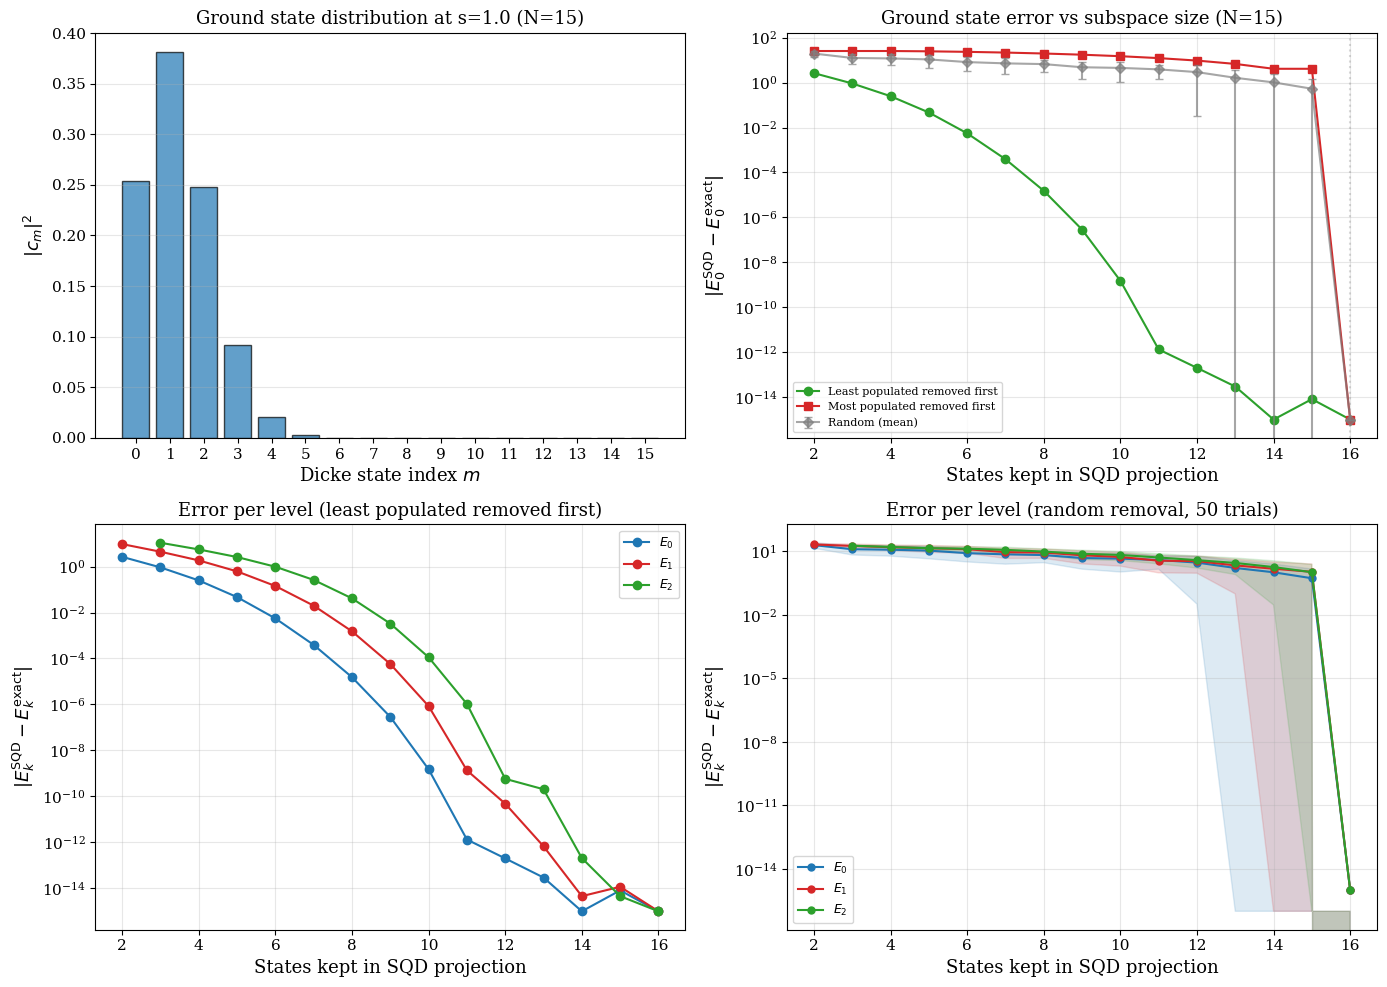

In [56]:
colors_level = ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e', '#9467bd', '#8c564b']

fig_rob, axes_rob = plt.subplots(2, 2, figsize=(14, 10))

# --- (a) Ground state Dicke distribution ---
ax = axes_rob[0, 0]
ax.bar(range(nq_rob), gs_probs, color='#1f77b4', alpha=0.7, edgecolor='black')
ax.set_xlabel('Dicke state index $m$')
ax.set_ylabel(r'$|c_m|^2$')
ax.set_title(f'Ground state distribution at s={s_rob} (N={N_rob})')
ax.set_xticks(range(nq_rob))
ax.grid(True, alpha=0.3, axis='y')

# --- (b) E0 error: three strategies ---
ax = axes_rob[0, 1]
ax.plot(rob_n_kept_least, rob_errors_least[:, 0] + 1e-15, 'o-',
        color='#2ca02c', markersize=6, label='Least populated removed first')
ax.plot(rob_n_kept_most, rob_errors_most[:, 0] + 1e-15, 's-',
        color='#d62728', markersize=6, label='Most populated removed first')
ax.errorbar(rob_n_kept_rand, rob_err_rand_mean[:, 0] + 1e-15,
            yerr=rob_err_rand_std[:, 0], fmt='D-', color='gray',
            markersize=5, capsize=3, alpha=0.7, label='Random (mean)')
ax.set_xlabel('States kept in SQD projection')
ax.set_ylabel(r'$|E_0^{\mathrm{SQD}} - E_0^{\mathrm{exact}}|$')
ax.set_yscale('log')
ax.set_title(f'Ground state error vs subspace size (N={N_rob})')
ax.axvline(x=nq_rob, color='gray', linestyle=':', alpha=0.3)
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# --- (c) All 3 levels, least-populated removal ---
ax = axes_rob[1, 0]
for k in range(n_levels_rob):
    ax.plot(rob_n_kept_least, rob_errors_least[:, k] + 1e-15, 'o-',
            color=colors_level[k], markersize=6, label=f'$E_{k}$')
ax.set_xlabel('States kept in SQD projection')
ax.set_ylabel(r'$|E_k^{\mathrm{SQD}} - E_k^{\mathrm{exact}}|$')
ax.set_yscale('log')
ax.set_title('Error per level (least populated removed first)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# --- (d) All 3 levels, random removal with spread ---
ax = axes_rob[1, 1]
for k in range(n_levels_rob):
    ax.fill_between(rob_n_kept_rand,
                     (rob_err_rand_mean[:, k] - rob_err_rand_std[:, k]).clip(1e-16),
                     rob_err_rand_mean[:, k] + rob_err_rand_std[:, k],
                     color=colors_level[k], alpha=0.15)
    ax.plot(rob_n_kept_rand, rob_err_rand_mean[:, k] + 1e-15, 'o-',
            color=colors_level[k], markersize=5, label=f'$E_{k}$')
ax.set_xlabel('States kept in SQD projection')
ax.set_ylabel(r'$|E_k^{\mathrm{SQD}} - E_k^{\mathrm{exact}}|$')
ax.set_yscale('log')
ax.set_title(f'Error per level (random removal, {n_random_trials} trials)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/sqd_robustness.pdf', bbox_inches='tight')
plt.show()

In [57]:
# Save results
save_dict = {
    's_exact': s_values_exact,
    'e_exact': exact_energies,
    's_sqd': s_values_sqd,
    'e_sqd_sim': sqd_sim_energies,
    # Physical state coverage (ideal SQD)
    'n_physical_states_sim': subspace_data_sim['n_physical_states'],
    'physical_prob_sim': subspace_data_sim['physical_prob'],
    # Robustness study
    'rob_N': N_rob,
    'rob_s': s_rob,
    'rob_gs_probs': gs_probs,
    'rob_n_kept_least': rob_n_kept_least,
    'rob_errors_least': rob_errors_least,
    'rob_n_kept_most': rob_n_kept_most,
    'rob_errors_most': rob_errors_most,
    'rob_n_kept_rand': rob_n_kept_rand,
    'rob_err_rand_mean': rob_err_rand_mean,
    'rob_err_rand_std': rob_err_rand_std,
}

if sqd_real_hw_results is not None:
    save_dict['s_sqd_hw'] = sqd_real_hw_results['s_values']
    save_dict['e_sqd_hw'] = sqd_real_hw_results['energies']

np.savez(f'{RESULTS_DIR}/sqd_only_spectrum.npz', **save_dict)

config_save = {
    'N_PARTICLES': N_PARTICLES,
    'LAM_0': LAM_0, 'CHI_0': CHI_0,
    'LAM_F': LAM_F, 'CHI_F': CHI_F,
    'N_S_POINTS': N_S_POINTS,
    'N_LEVELS': N_LEVELS,
    'SQD_SHOTS': SQD_SHOTS,
    'T_SCALE': T_SCALE,
    'N_STEPS_SCALE': N_STEPS_SCALE,
    'encoding': 'one-hot (N+1 qubits, N+1 physical states)',
    'postselection': True,
    'RUN_ON_HARDWARE': RUN_ON_HARDWARE,
    'BACKEND_NAME': BACKEND_NAME if RUN_ON_HARDWARE else None,
    'robustness_N': N_rob,
    'robustness_s': s_rob,
    'robustness_n_random_trials': n_random_trials,
}
with open(f'{RESULTS_DIR}/sqd_config.json', 'w') as f:
    json.dump(config_save, f, indent=2)

print(f'Results saved to {RESULTS_DIR}/')

Results saved to results_lipkin_spectrum/
